In [4]:
import pandas as pd

df = pd.read_csv("pop_1836-1866.csv", encoding="utf-8", sep=";")
df2 = pd.read_csv("pop1872-1886.csv", encoding="utf-8", sep=";")
df3 = pd.read_csv("pop_1891-1906.csv", encoding="utf-8", sep=";")

# Même type pour les trois clés
for d in [df, df2, df3]:
    d["Nom de l'unité d'analyse"] = d["Nom de l'unité d'analyse"].astype(str).str.strip()

# Jointures
df_g = df.merge(
    df2,
    on="Nom de l'unité d'analyse",
    how="outer"
)

df_g = df_g.merge(
    df3,
    on="Nom de l'unité d'analyse",
    how="outer"
)

In [6]:
df_g =df_g[df_g["Code de l'unité géographique_x"]==1]

In [18]:
df_g.reset_index()
df_g = df_g.loc[
    :,
    df_g.columns.str.contains(r"\d{4}$") |
    (df_g.columns == "Nom de l'unité d'analyse")
]

In [19]:
df_g

,Nom de l'unité d'analyse,Nombre d'habitants en 1836,Nombre d'habitants en 1841,Nombre d'habitants en 1846,Nombre d'habitants en 1851,Nombre d'habitants en 1861,Nombre d'habitants en 1866,"Population légale, variations par département, nombre des habitants, (population ramenée au territoire actuel), 1861","Population légale, variations par département, nombre des habitants, (population ramenée au territoire actuel), 1866","Population légale, variations par département, nombre des habitants, 1891","Population légale, variations par département, nombre des habitants, 1896","Population légale, variations par département, nombre des habitants, 1901","Population légale, variations par département, nombre des habitants, 1906"
2,AIN,346188.0,355694.0,367362.0,372939.0,369767.0,371643.0,369767.0,371643.0,356907.0,351509.0,350416.0,345856.0
3,AISNE,527095.0,542213.0,557422.0,558989.0,564597.0,565025.0,564597.0,565025.0,545493.0,541513.0,535583.0,534495.0
10,ALLIER,309270.0,311361.0,329540.0,336758.0,356432.0,376164.0,356432.0,376164.0,424382.0,424378.0,422024.0,417961.0
11,ALPES(BASSES-),159045.0,156055.0,156675.0,152070.0,146368.0,143000.0,146368.0,143000.0,124285.0,118142.0,115021.0,113126.0
12,ALPES(HAUTES-),131162.0,132584.0,133100.0,132038.0,125100.0,122117.0,125100.0,122117.0,115522.0,113229.0,109510.0,107498.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,VENDEE,341312.0,356453.0,376184.0,383734.0,395695.0,404473.0,395695.0,404473.0,442355.0,441735.0,441311.0,442777.0
453,VIENNE,288002.0,294250.0,308391.0,317305.0,322028.0,324527.0,322028.0,324527.0,344355.0,338114.0,336343.0,333621.0
454,VIENNE(HAUTE-),293011.0,292848.0,314739.0,319379.0,319595.0,326037.0,319595.0,326037.0,372878.0,375724.0,381753.0,385732.0
462,VOSGES,411034.0,419992.0,427894.0,427409.0,415485.0,418998.0,415485.0,418998.0,410196.0,421412.0,421104.0,429812.0


In [20]:
df_long = df_g.melt(
    id_vars="Nom de l'unité d'analyse",
    var_name="année",
    value_name="population"
)
df_long["année"] = df_long["année"].str.extract(r"(\d{4})").astype(int)

In [21]:
df_long

,Nom de l'unité d'analyse,année,population
0,AIN,1836,346188.0
1,AISNE,1836,527095.0
2,ALLIER,1836,309270.0
3,ALPES(BASSES-),1836,159045.0
4,ALPES(HAUTES-),1836,131162.0
...,...,...,...
1027,VENDEE,1906,442777.0
1028,VIENNE,1906,333621.0
1029,VIENNE(HAUTE-),1906,385732.0
1030,VOSGES,1906,429812.0


C:\Users\maritp02\AppData\Local\Temp\ipykernel_13928\366166598.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


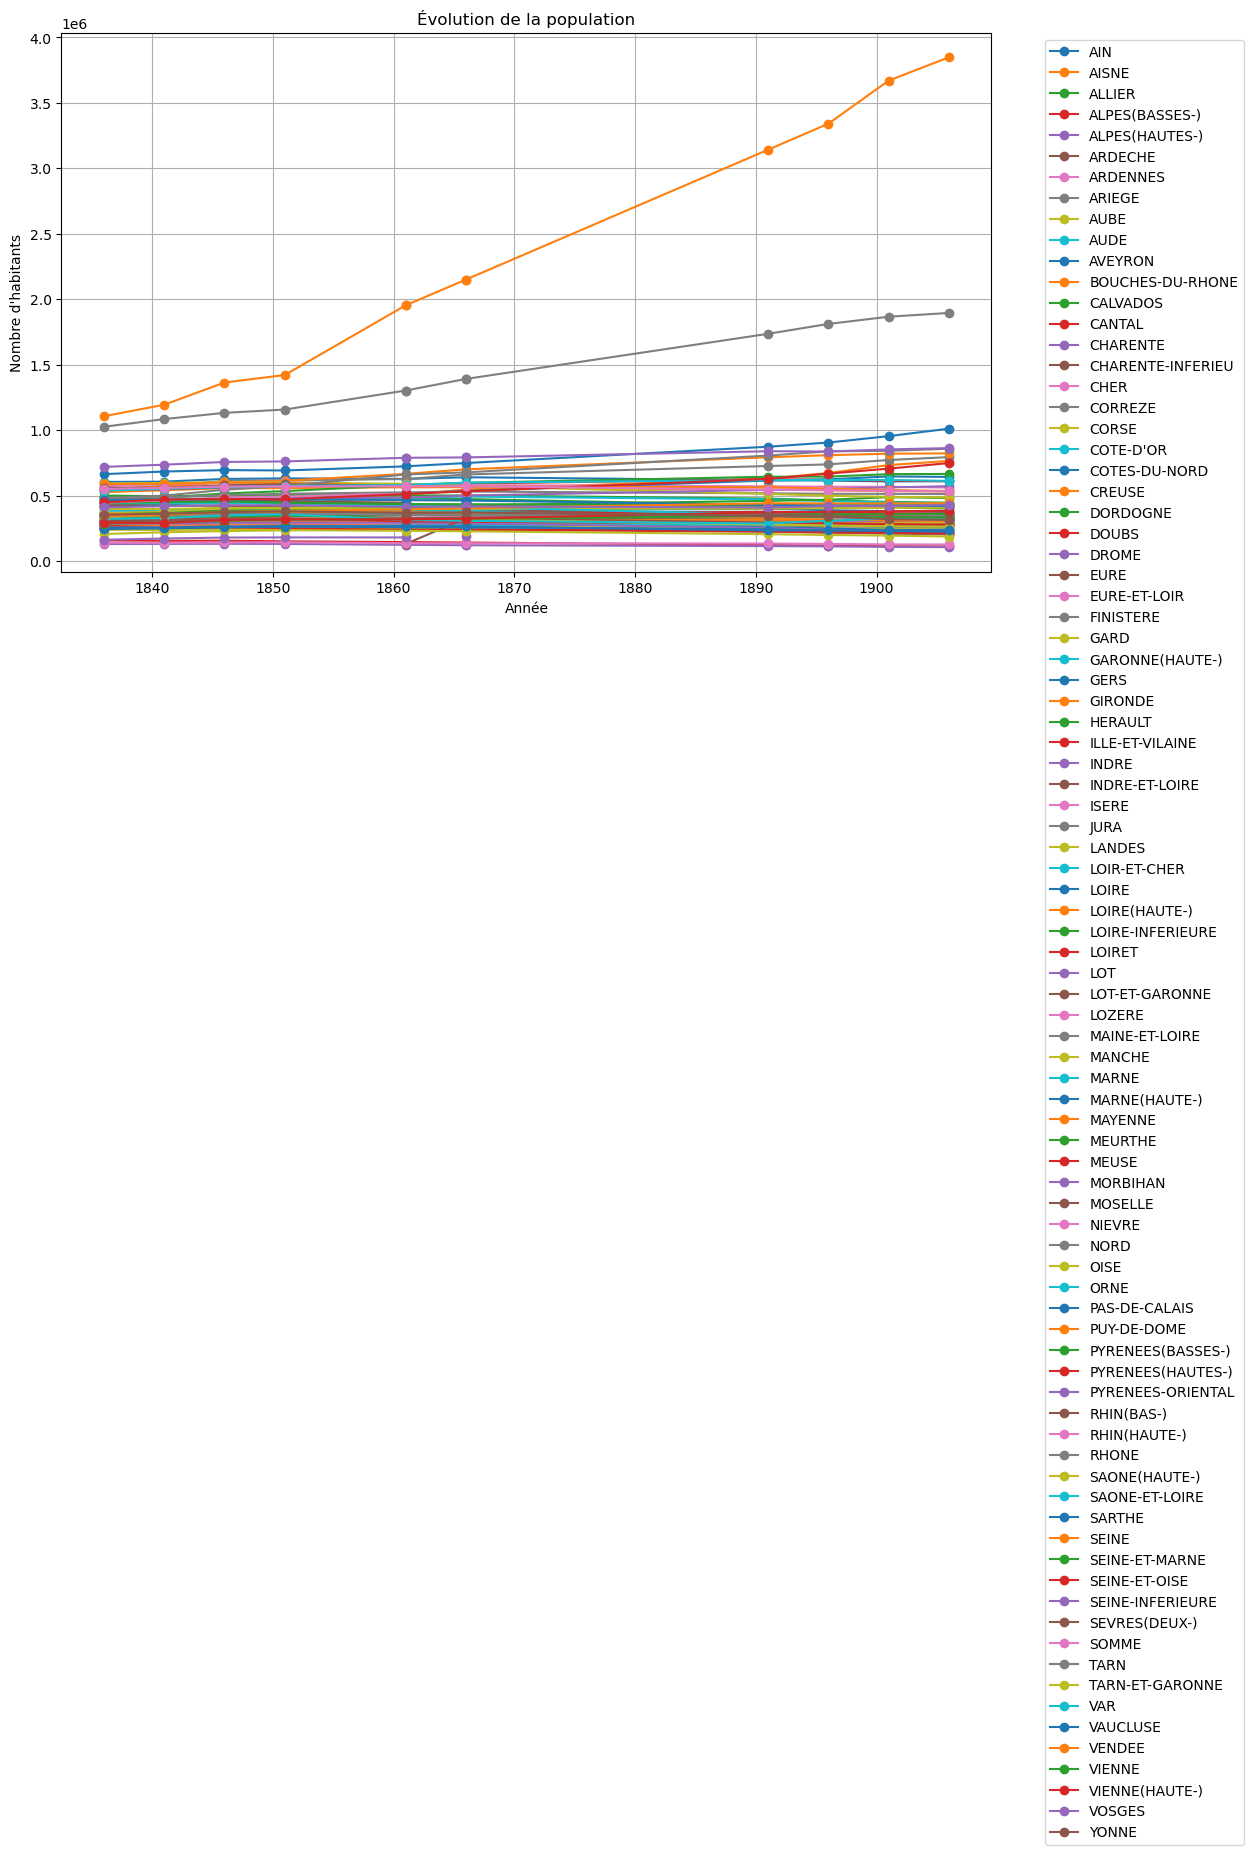

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for unite, data in df_long.groupby("Nom de l'unité d'analyse"):
    data = data.sort_values("année")
    plt.plot(
        data["année"],
        data["population"],
        marker="o",
        label=unite
    )

plt.xlabel("Année")
plt.ylabel("Nombre d'habitants")
plt.title("Évolution de la population")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()

plt.show()


===== PLUS GRANDES HAUSSES EN VALEUR ABSOLUE =====
     departement  population_debut  population_fin  variation_absolue  variation_relative
           SEINE           1106891         3848618            2741727          247.696205
            NORD           1026417         1895861             869444           84.706703
BOUCHES-DU-RHONE            362325          765918             403593          111.389774
           RHONE            482024          858907             376883           78.187601
   PAS-DE-CALAIS            664654         1012466             347812           52.329784
   SEINE-ET-OISE            449582          749753             300171           66.766685
         GIRONDE            555809          823925             268116           48.238873
       FINISTERE            546955          795103             248148           45.368997
           LOIRE            412497          643943             231446           56.108529
LOIRE-INFERIEURE            470768          6667

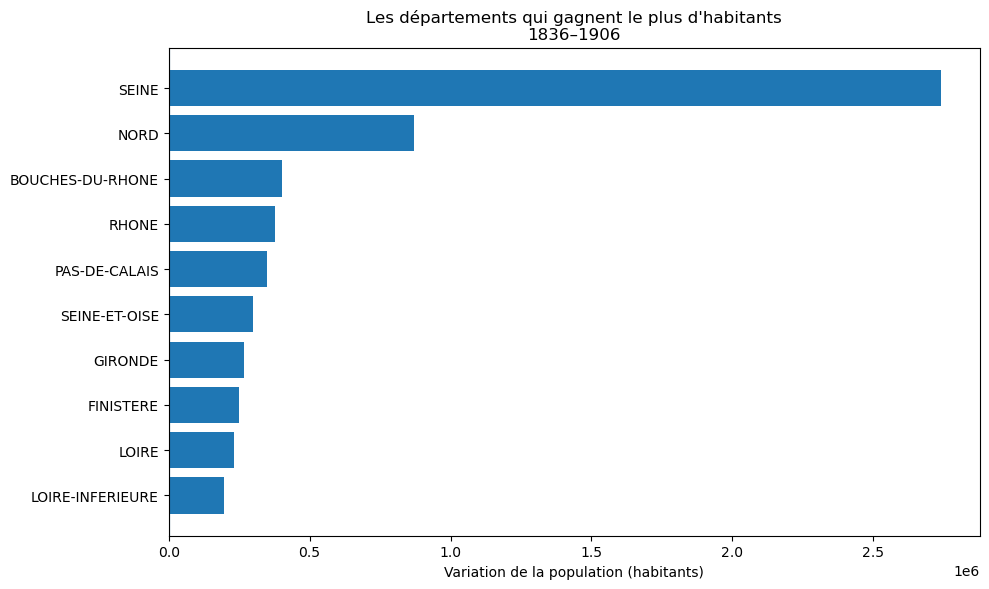

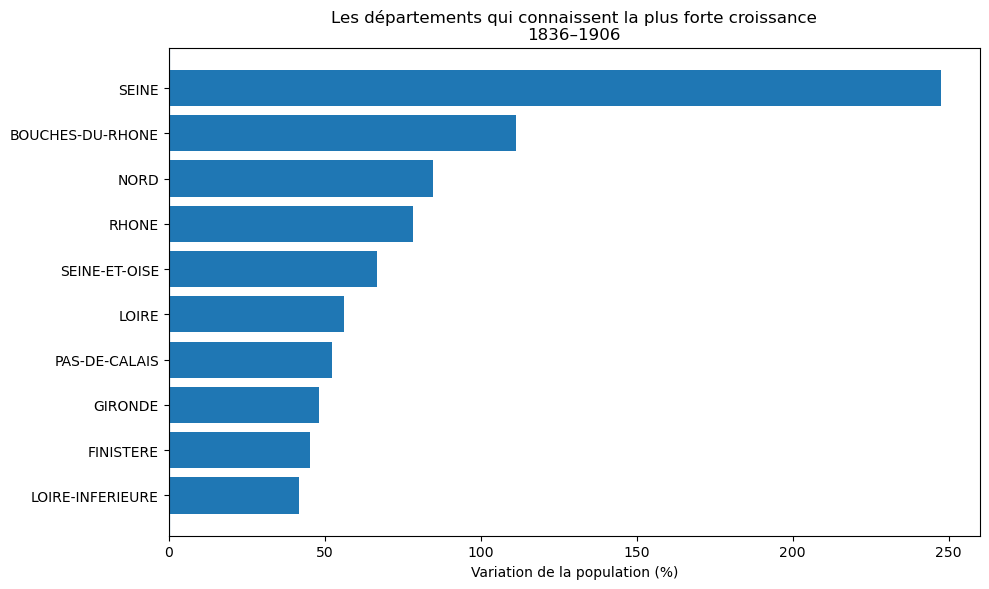

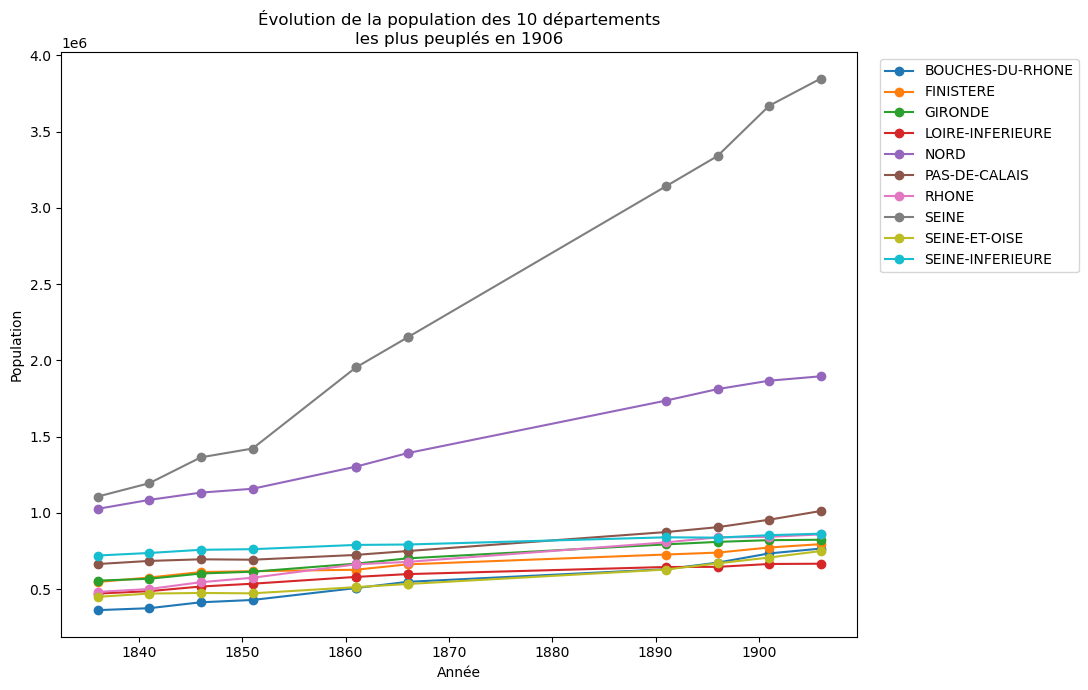

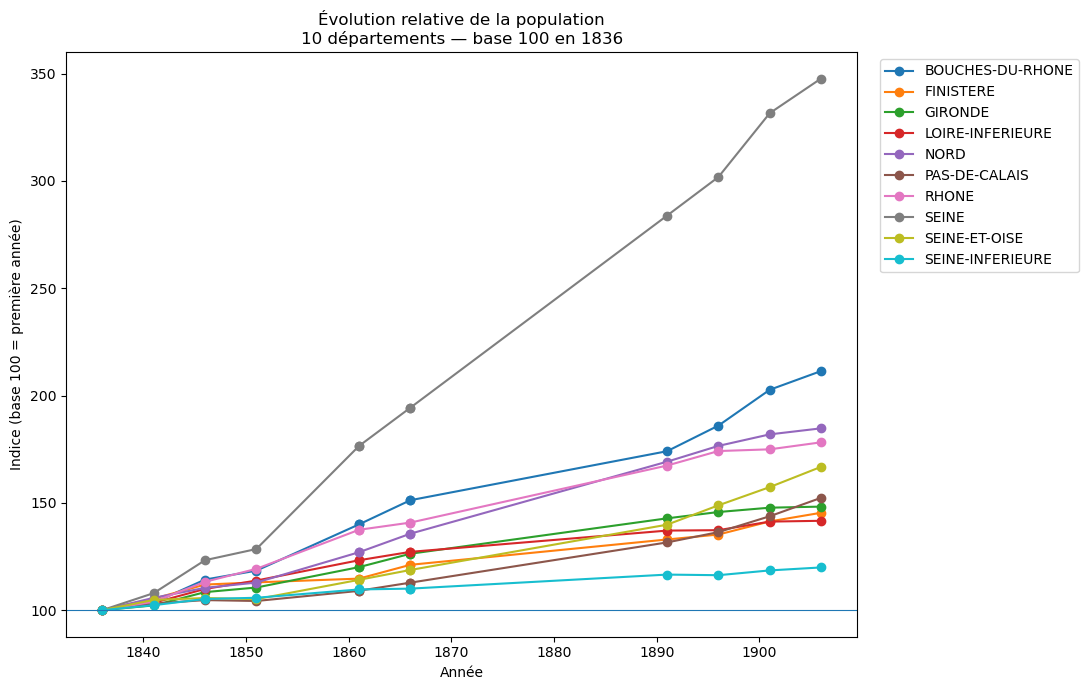

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 0. PARAMÈTRES
# ============================================================

annee_debut = 1836
annee_fin = 1906

# Nombre de départements à afficher
n = 10


# ============================================================
# 1. NETTOYAGE DES DONNÉES
# ============================================================

# On fait une copie pour ne pas modifier le dataframe original
data = df_long.copy()

# Renommage pratique des colonnes
data = data.rename(columns={
    "Nom de l'unité d'analyse": "departement",
    "année": "annee",
    "population": "population"
})

# On supprime les lignes sans population
data = data.dropna(subset=["population"])

# Conversion des types
data["annee"] = pd.to_numeric(data["annee"], errors="coerce")
data["population"] = pd.to_numeric(data["population"], errors="coerce")

# Suppression des années/populations invalides
data = data.dropna(subset=["annee", "population"])

# On s'assure que les années sont des entiers
data["annee"] = data["annee"].astype(int)

# Population entière
data["population"] = data["population"].round().astype(int)


# ============================================================
# 2. EXTRAIRE LES DEUX ANNÉES
# ============================================================

debut = (
    data[data["annee"] == annee_debut]
    [["departement", "population"]]
    .rename(columns={"population": "population_debut"})
)

fin = (
    data[data["annee"] == annee_fin]
    [["departement", "population"]]
    .rename(columns={"population": "population_fin"})
)

# On ne garde que les départements présents aux deux dates
comparaison = debut.merge(fin, on="departement", how="inner")


# ============================================================
# 3. CALCULER LES INDICATEURS
# ============================================================

# Variation absolue
comparaison["variation_absolue"] = (
    comparaison["population_fin"]
    - comparaison["population_debut"]
)

# Variation relative en %
comparaison["variation_relative"] = (
    (comparaison["population_fin"]
     - comparaison["population_debut"])
    / comparaison["population_debut"]
    * 100
)

# Facteur de croissance
comparaison["facteur"] = (
    comparaison["population_fin"]
    / comparaison["population_debut"]
)

# Indice base 100
comparaison["indice_100"] = comparaison["facteur"] * 100


# ============================================================
# 4. AFFICHER LES TABLEAUX DE RÉSULTATS
# ============================================================

print("\n===== PLUS GRANDES HAUSSES EN VALEUR ABSOLUE =====")

print(
    comparaison
    .sort_values("variation_absolue", ascending=False)
    [["departement",
      "population_debut",
      "population_fin",
      "variation_absolue",
      "variation_relative"]]
    .head(20)
    .to_string(index=False)
)

print("\n===== PLUS GRANDES BAISSES EN VALEUR ABSOLUE =====")

print(
    comparaison
    .sort_values("variation_absolue")
    [["departement",
      "population_debut",
      "population_fin",
      "variation_absolue",
      "variation_relative"]]
    .head(20)
    .to_string(index=False)
)

print("\n===== PLUS FORTES CROISSANCES EN % =====")

print(
    comparaison
    .sort_values("variation_relative", ascending=False)
    [["departement",
      "population_debut",
      "population_fin",
      "variation_absolue",
      "variation_relative"]]
    .head(20)
    .to_string(index=False)
)

print("\n===== PLUS FORTES BAISSES EN % =====")

print(
    comparaison
    .sort_values("variation_relative")
    [["departement",
      "population_debut",
      "population_fin",
      "variation_absolue",
      "variation_relative"]]
    .head(20)
    .to_string(index=False)
)


# ============================================================
# 5. GRAPHIQUE 1
# POPULATION GAGNÉE/PERDUE EN NOMBRE D'HABITANTS
# ============================================================

top_absolu = (
    comparaison
    .sort_values("variation_absolue")
    .tail(n)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_absolu["departement"],
    top_absolu["variation_absolue"]
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("Variation de la population (habitants)")
plt.ylabel("")
plt.title(
    f"Les départements qui gagnent le plus d'habitants\n"
    f"{annee_debut}–{annee_fin}"
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. GRAPHIQUE 2
# CROISSANCE EN POURCENTAGE
# ============================================================

top_relatif = (
    comparaison
    .sort_values("variation_relative")
    .tail(n)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_relatif["departement"],
    top_relatif["variation_relative"]
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("Variation de la population (%)")
plt.ylabel("")
plt.title(
    f"Les départements qui connaissent la plus forte croissance\n"
    f"{annee_debut}–{annee_fin}"
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. GRAPHIQUE 3
# ÉVOLUTION ABSOLUE DES 10 DÉPARTEMENTS
# LES PLUS PEUPLÉS À LA FIN DE LA PÉRIODE
# ============================================================

top_departements = (
    comparaison
    .sort_values("population_fin", ascending=False)
    .head(n)["departement"]
    .tolist()
)

evolution = data[
    data["departement"].isin(top_departements)
    & data["annee"].between(annee_debut, annee_fin)
]

plt.figure(figsize=(11, 7))

for departement, groupe in evolution.groupby("departement"):

    groupe = groupe.sort_values("annee")

    plt.plot(
        groupe["annee"],
        groupe["population"],
        marker="o",
        label=departement
    )

plt.xlabel("Année")
plt.ylabel("Population")
plt.title(
    f"Évolution de la population des {n} départements\n"
    f"les plus peuplés en {annee_fin}"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. GRAPHIQUE 4
# LES MÊMES DÉPARTEMENTS EN INDICE 100
# ============================================================

evolution_indice = evolution.copy()

# Population de chaque département à la première année
population_reference = (
    evolution_indice[
        evolution_indice["annee"] == annee_debut
    ]
    .set_index("departement")["population"]
)

# Calcul de l'indice base 100
evolution_indice["indice_100"] = (
    evolution_indice.apply(
        lambda ligne:
        ligne["population"]
        / population_reference[ligne["departement"]]
        * 100,
        axis=1
    )
)

plt.figure(figsize=(11, 7))

for departement, groupe in evolution_indice.groupby("departement"):

    groupe = groupe.sort_values("annee")

    plt.plot(
        groupe["annee"],
        groupe["indice_100"],
        marker="o",
        label=departement
    )

plt.axhline(100, linewidth=0.8)

plt.xlabel("Année")
plt.ylabel("Indice (base 100 = première année)")
plt.title(
    f"Évolution relative de la population\n"
    f"{n} départements — base 100 en {annee_debut}"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

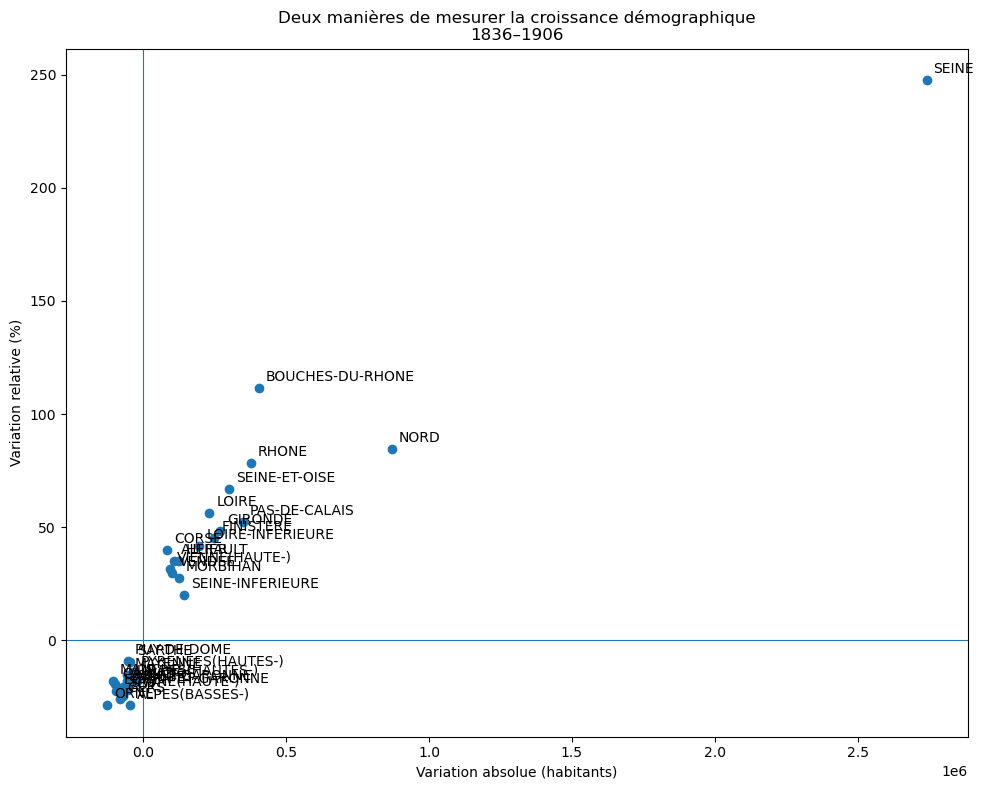

In [26]:
# ============================================================
# 9. GRAPHIQUE 5
# MÊMES DÉPARTEMENTS :
# VARIATION ABSOLUE VS VARIATION RELATIVE
# ============================================================

# On prend les départements ayant les plus fortes variations
# absolues OU relatives
candidats = pd.concat([
    comparaison.nlargest(15, "variation_absolue"),
    comparaison.nlargest(15, "variation_relative"),
    comparaison.nsmallest(15, "variation_absolue"),
    comparaison.nsmallest(15, "variation_relative")
]).drop_duplicates("departement")

# Pour faciliter la comparaison
candidats = candidats.sort_values("variation_relative")

plt.figure(figsize=(10, 8))

plt.scatter(
    candidats["variation_absolue"],
    candidats["variation_relative"]
)

for _, ligne in candidats.iterrows():

    plt.annotate(
        ligne["departement"],
        (
            ligne["variation_absolue"],
            ligne["variation_relative"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Variation absolue (habitants)")
plt.ylabel("Variation relative (%)")

plt.title(
    f"Deux manières de mesurer la croissance démographique\n"
    f"{annee_debut}–{annee_fin}"
)

plt.tight_layout()
plt.show()

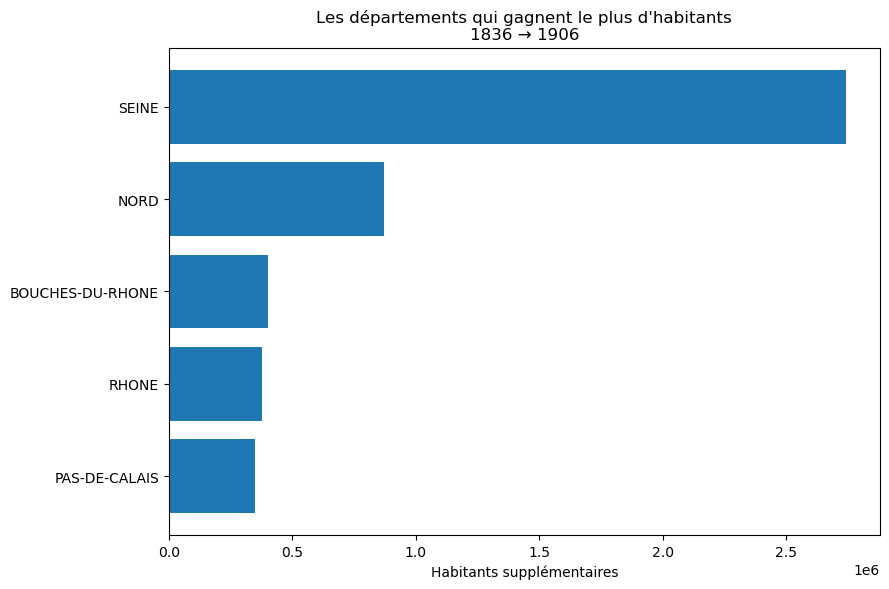

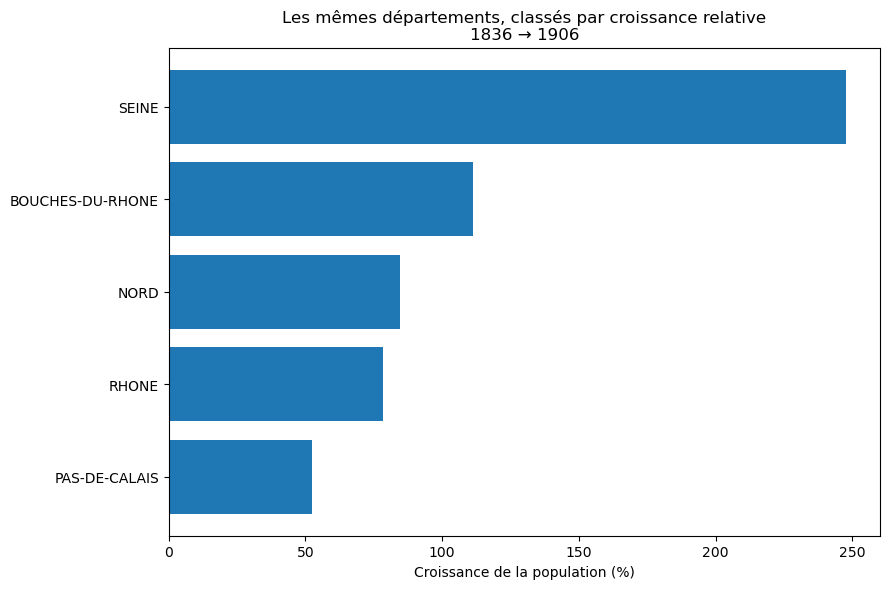

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PARAMÈTRES
# ------------------------------------------------------------

annee_debut = 1836
annee_fin = 1906
n = 5

df=df_long.copy()

# ------------------------------------------------------------
# EXTRACTION DES DONNÉES
# ------------------------------------------------------------

debut = (
    df[df["année"] == annee_debut]
    [["Nom de l'unité d'analyse", "population"]]
    .rename(columns={"population": "population_debut"})
)

fin = (
    df[df["année"] == annee_fin]
    [["Nom de l'unité d'analyse", "population"]]
    .rename(columns={"population": "population_fin"})
)

data = debut.merge(
    fin,
    on="Nom de l'unité d'analyse"
)


# ------------------------------------------------------------
# CALCULS
# ------------------------------------------------------------

data["variation_absolue"] = (
    data["population_fin"]
    - data["population_debut"]
)

data["variation_relative"] = (
    (data["population_fin"] - data["population_debut"])
    / data["population_debut"]
    * 100
)


# ------------------------------------------------------------
# ON PREND LES 10 DÉPARTEMENTS
# QUI ONT LE PLUS AUGMENTÉ EN VALEUR ABSOLUE
# ------------------------------------------------------------

selection = (
    data
    .nlargest(n, "variation_absolue")
    .copy()
)


# ------------------------------------------------------------
# GRAPHIQUE 1 : NOMBRE D'HABITANTS GAGNÉS
# ------------------------------------------------------------

graph1 = (
    selection
    .sort_values("variation_absolue")
)

plt.figure(figsize=(9, 6))

plt.barh(
    graph1["Nom de l'unité d'analyse"],
    graph1["variation_absolue"]
)

plt.xlabel("Habitants supplémentaires")
plt.title(
    f"Les départements qui gagnent le plus d'habitants\n"
    f"{annee_debut} → {annee_fin}"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPHIQUE 2 : POURCENTAGE DE CROISSANCE
# ------------------------------------------------------------

graph2 = (
    selection
    .sort_values("variation_relative")
)

plt.figure(figsize=(9, 6))

plt.barh(
    graph2["Nom de l'unité d'analyse"],
    graph2["variation_relative"]
)

plt.xlabel("Croissance de la population (%)")
plt.title(
    f"Les mêmes départements, classés par croissance relative\n"
    f"{annee_debut} → {annee_fin}"
)

plt.tight_layout()
plt.show()

In [29]:
df_long.to_csv("df_long.csv", index=False, encoding="utf-8")